# Experiment 1: Data Exploration, Preprocessing, and Outlier Detection

**Objective:**
1. Load a dataset using Pandas.
2. Check for missing values and duplicate records.
3. Detect outliers using the Interquartile Range (IQR) method and remove them.
4. Visualize data distribution using a Histogram and a Box Plot.

### Step 1: Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### Step 2: Load the Dataset

In [2]:
# Load student performance dataset
df = pd.read_csv('./data_1.csv')

# Display first 5 rows and shape
print("First 5 rows of dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)

First 5 rows of dataset:
  Student_ID  Study_Hours  ...  Internal_Marks  Final_Score
0       S001          5.3  ...            61.4         37.3
1       S002          2.9  ...            73.3         68.7
2       S003          6.2  ...            55.3         65.5
3       S004          6.5  ...            62.9         65.2
4       S005          NaN  ...            40.1         56.1

[5 rows x 6 columns]

Dataset Shape: (200, 6)


### Step 3: Check for Missing Values and Duplicates

In [3]:
# Check missing values per column
print("Missing Values per Column:")
print(df.isnull().sum())
print()

# Check total duplicate rows
duplicates = df.duplicated().sum()
print("Total Duplicate Rows:", duplicates)

Missing Values per Column:
Student_ID          0
Study_Hours         3
Attendance          3
Assignment_Score    3
Internal_Marks      3
Final_Score         3
dtype: int64

Total Duplicate Rows: 8


### Step 4: Detect and Remove Outliers using IQR Method

**Formulas:**
- $Q_1$ = 25th percentile
- $Q_3$ = 75th percentile
- $IQR = Q_3 - Q_1$
- $\text{Lower Bound} = Q_1 - 1.5 \times IQR$
- $\text{Upper Bound} = Q_3 + 1.5 \times IQR$

In [4]:
col = "Final_Score"

# Calculate Quartiles and IQR
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

# Define outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 (25th percentile) : {Q1:.2f}")
print(f"Q3 (75th percentile) : {Q3:.2f}")
print(f"IQR (Q3 - Q1)        : {IQR:.2f}")
print(f"Lower Bound          : {lower_bound:.2f}")
print(f"Upper Bound          : {upper_bound:.2f}")

# Filter out rows with outliers in Final_Score
df_cleaned = df[df[col].between(lower_bound, upper_bound)]

print(f"\nOriginal row count   : {len(df)}")
print(f"Cleaned row count    : {len(df_cleaned)}")
print(f"Outlier rows removed : {len(df) - len(df_cleaned)}")

Q1 (25th percentile) : 48.70
Q3 (75th percentile) : 61.30
IQR (Q3 - Q1)        : 12.60
Lower Bound          : 29.80
Upper Bound          : 80.20

Original row count   : 200
Cleaned row count    : 193
Outlier rows removed : 7


### Step 5: Visualize Data Distribution (Histogram & Box Plot)

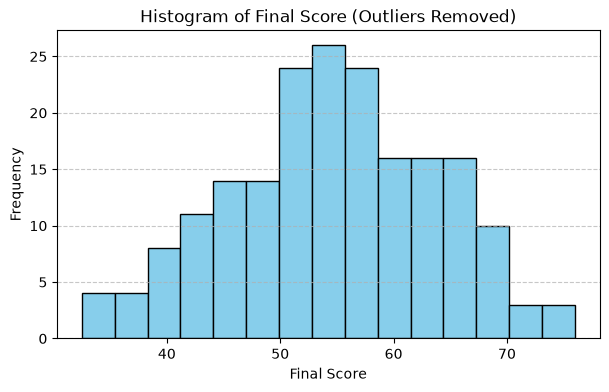

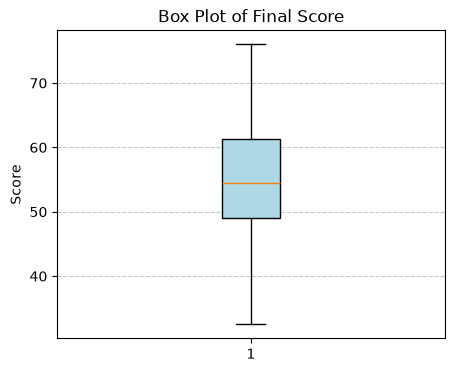

In [5]:
# 1. Histogram of Final Score
plt.figure(figsize=(7, 4))
plt.hist(df_cleaned[col], bins=15, color='skyblue', edgecolor='black')
plt.title("Histogram of Final Score (Outliers Removed)")
plt.xlabel("Final Score")
plt.ylabel("Frequency")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 2. Box Plot of Final Score
plt.figure(figsize=(5, 4))
plt.boxplot(df_cleaned[col].dropna(), patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title("Box Plot of Final Score")
plt.ylabel("Score")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()